In [1]:
print("run")
import numpy as np
import matplotlib.pyplot as plt
import pywt
import scipy as sp
from scipy.signal import ShortTimeFFT
from scipy.signal.windows import gaussian
import time
#import utils
import os

run


In [20]:
def energy(f, B):# f = |e|B/(2pi*(m_e + E/c^2)) => E/c^2 = |e|B/(2pi f) - m_e
    ### working in natural units: E/c^2 = E
    ### units [E] = [m] = eV
    m_e = 511e3 # eV
    e = np.sqrt(4*np.pi/137)

    return e*B/(2*np.pi * f) - m_e

def energy_SI(f, B):
    m_e = 9.1093837139e-31
    e = 1.60217733e-19
    c = 299792458
    return (e*B/(2*np.pi * f) - m_e)*c**2 * 6.24e18 # J -> eV conversion

f = 25970200000.0
B = 0.96

print((energy_SI(f, B)))

17755.624340167975


In [4]:
m = np.ones((10, 5))
print(m)
m[:, 0]

[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]


array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [13]:
path= '/nfs/roberts/pi/pi_kmh66/spreadsheetData/SpreadsheetRow51_UNetScattering_CCA/Trap_CCA_long_trap_44_UNetScattering_1/Trap_CCA_long_trap_44_UNetScattering_1/results/'
files = list(os.scandir(path))
print(files[-2])

dirs = [i[0] for i in os.walk(path)]

<DirEntry 'joblist_Trap_CCA_long_trap_44_UNetScattering_1.txt'>


In [16]:
print(len(dirs))

6028


### Loading in data, can be combined with GetTimeStream notebook

In [2]:
utils.retrieval(1)

In [43]:
rng = np.linspace(1, 100, 5, endpoint=True)
rng

array([  1.  ,  25.75,  50.5 ,  75.25, 100.  ])

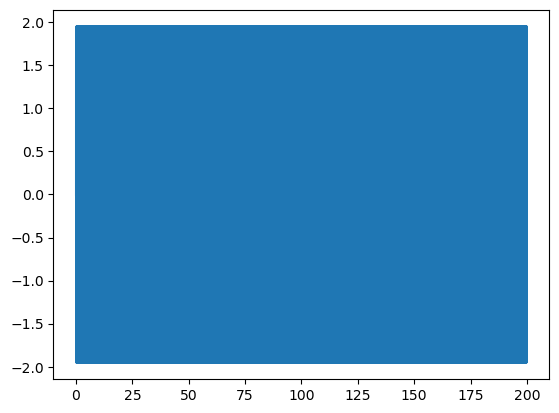

[ 0.     0.005  0.01  ... -0.015 -0.01  -0.005]


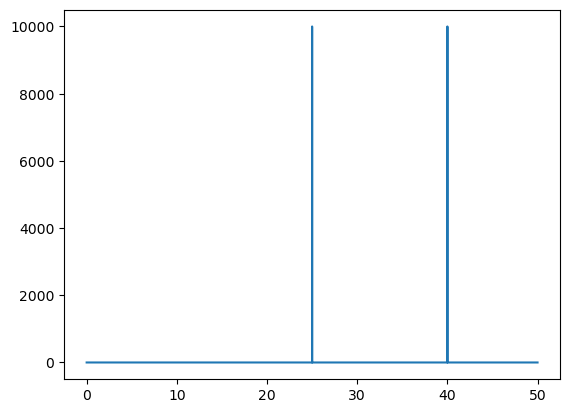

In [25]:
y = lambda x: np.sin(2*np.pi*40*x) + np.sin(2*np.pi*25*x)

fs = 100
T = 1/fs
t = np.arange(0, 200, T)
signal = y(t)
N = len(signal)

plt.plot(t, signal)
plt.show()

f = np.abs(np.fft.fft(signal))

fs = np.fft.fftfreq(N, d=T)
print(fs)

plt.plot(fs[:N//2], f[:N//2])
plt.show()

In [2]:
def recon_on_many(itr, fmix=110e6, units=1e6, magnitude=False, rel=False, B=20, C=3):
    path = '/nfs/roberts/pi/pi_kmh66/spreadsheetData/SpreadsheetRow51_UNetScattering_CCA/Trap_CCA_long_trap_44_UNetScattering_1/Trap_CCA_long_trap_44_UNetScattering_1/results/'
    files = list(os.scandir(path))
    length = len(files)
    itr = itr
    i = -1
    error = np.zeros((2, itr-1))


    
    while i < itr:
        filepath = path
        print(filepath)
        
        if not files[i].is_dir():
            continue
        else:
            i += 1
            print(f"{i}/{itr}")
    
            name = files[i].name
            filepath = filepath + name
    
            subfiles = os.scandir(filepath)
    
            for file in subfiles:
                if file.name.endswith('.egg'):
                    eggfilepath = filepath+"/"+file.name
    
            jsonfilepath = filepath+'/LocustEventProperties.json'
    
            with open(jsonfilepath, 'r') as file:
                metadata = json.load(file)
    
            file = EggFileReader(eggfilepath)
            stream = file.load_ts_stream()[0][0][0]
            I_data = stream.real
            Q_data = stream.imag
    
        
            if (i-1) % 10 == 0: print(f"{i}/{itr-1}")
            file_id = obj[i].name[2:-4]
            fs = float(metadata['run-parameters']['sampling-freq-mega-hz'])*units
            f = metadata['0']['0']['output-avg-frequency']
            start = metadata['0']['0']['start-time']
            end = metadata['0']['0']['end-time']
            
            actual = (f - fmix)/1e6
        
            idx = int(fs*start)
            edx = int(fs*end)
            
            data = I_data[idx:edx] + 1j*Q_data[idx:edx]
            T  = float(data.size)/fs
            N  = len(data)
            t  = np.arange(N) / fs
            signal_locust = data * (-1.0)**np.arange(N)
    
            signal = signal_locust * np.exp(-1j * 2*np.pi * fmix * t)
            
            t_center = 0.0015     # seconds -- time where there is a track
            window   = 5e-3       # 5 ms around it
            i0 = max(0, int((t_center - window/2) * fs))
            i1 = min(N, int((t_center + window/2) * fs))
            signal = signal[i0:i1]
            signal_locust = signal_locust[i0:i1]
            N = len(signal)
            t = np.arange(N) / fs
        
            ### STFT
            win_len = min(1024, N // 8)     
            hop     = max(1, win_len // 8)
            
            win = gaussian(win_len, std=win_len/6, sym=True)
            SFT = ShortTimeFFT(win, hop=hop, fs=fs, fft_mode='centered',
                               scale_to='magnitude')
            Sxx = SFT.stft(signal)
            f_stft = SFT.f
            t_stft = SFT.t(N)
    
            ### CWT
            wavelet = f'cmor{B}-{C}'
            
            fmin     = 50e5
            fmax     = 50e6
            n_voices = 96
             
            freqs_pos = np.logspace(np.log10(fmin), np.log10(fmax), n_voices)
            scales    = pywt.frequency2scale(wavelet, freqs_pos / fs)
    
            coefs, f_returned = pywt.cwt(
                signal, scales, wavelet, sampling_period=1/fs, method='fft'
            )
            mag = np.abs(coefs)
    
            t_cwt = np.arange(mag.shape[1]) / fs
            idx_cwt = N//2
            #print("At CWT time:", t_cwt[idx_cwt]*1e3, "ms")
            idx_stft = max(np.where(np.round(t_stft*1e3 - t_cwt[idx_cwt]*1e3, 3) == 0.0)[0])
            #print("At STFT time:", t_stft[idx_stft]*1e3, "ms")
            
            magcwt = mag[:, idx_cwt]
            magstft = np.abs(Sxx[:, idx_stft])
            
            f_CWT = freqs_pos[np.argmax(magcwt)]/1e6
            #print(f"\nFrequency CWT: {f_CWT}, \nDifference Error: {f_CWT-actual}\n")
            
            f_STFT = f_stft[np.argmax(magstft)]/1e6
            #print(f"Frequency STFT: {f_STFT}, \nDifference Error: {f_STFT-actual}")
                
            if rel: denom=actual
            else: denom=1
        
            if magnitude:
                error[0,i-1]=np.abs((f_CWT-actual)/denom)
                error[1,i-1]=np.abs((f_STFT-actual)/denom)
            else:
                error[0,i-1] = (f_CWT-actual)/denom
                error[1,i-1] = (f_STFT-actual)/denom
            
        print("COMPLETE")    
        np.save(f"error_{itr}_mag{magnitude}_B{B}_C{C}", error)

In [3]:
recon_on_many(1, B=15, C=3)

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)


KeyboardInterrupt



KeyboardInterrupt: 

[[-4256.61882068 -4366.07777006 -4174.93443492 -4364.08522245
  -4418.47368527 -4385.96154079 -4389.14056505 -4417.83458446
  -4259.4529551  -4172.53937903]
 [-4163.81655574 -4372.0778162  -4180.93770602 -4384.90610858
  -4424.47264789 -4391.96113227 -4395.14065511 -4423.83436134
  -4261.3928175  -4178.54259063]]
CWT | STFT
Mean
[-4336.95328653 -4333.17108896]
STD
[80.6963405  97.21146862]


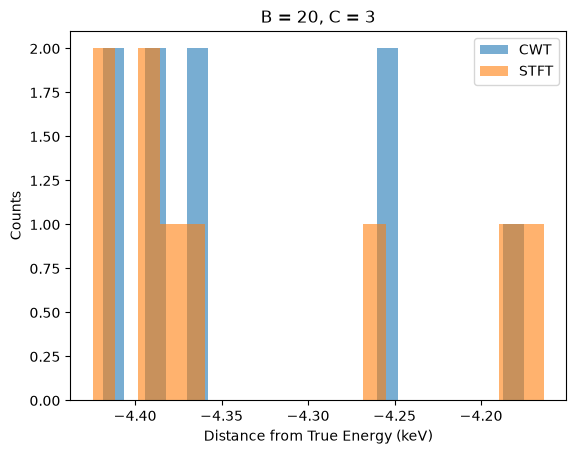

[[ 4.19113916 -0.20758945 -0.20758945 -0.01420267 -0.20758945 -0.20758945
  -0.20758945 -0.20758945  1.78113047 -0.20758945]
 [ 0.          0.09082031  0.09082031  0.09082031  0.09082031  0.09082031
   0.09082031  0.09082031  4.70886076  0.09082031]]
CWT | STFT
Mean
[0.52361448 0.59384477]
STD
[1.43485524 1.45515343]


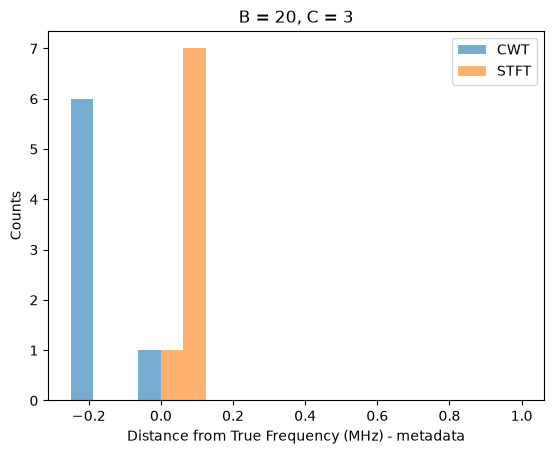

[[-0.68803413 -0.14068745 -0.06276501  0.73902857 -0.10783149 -0.18175836
  -0.04532915 -0.16653966 -2.87131818 -0.24362758]
 [-4.87917329  0.15772231  0.23564475  0.84405155  0.19057827  0.1166514
   0.25308061  0.1318701   0.0564121   0.05478218]]
CWT | STFT
Mean
[-0.39169276 -0.32146247]
STD
[0.94171237 1.62630003]


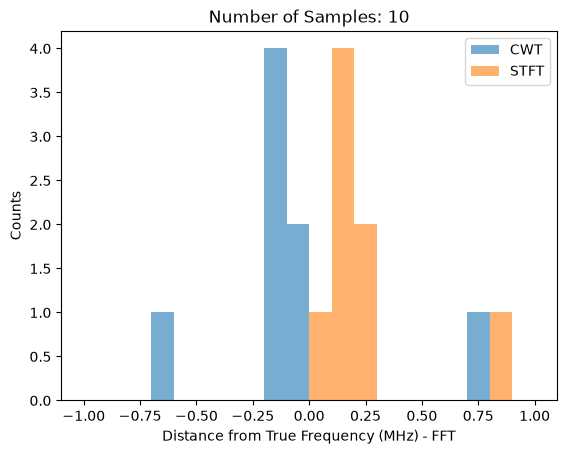

[[ 2.07955873  2.19322956  2.94023782  1.18010164  2.09900205  2.17802712
   1.50147671  2.10248997  2.01911768  2.15764068]
 [54.70766601  4.46041186  4.24513939  5.08343171  3.90030311  4.61126603
   3.5321554   3.46087745 54.5361636   6.73929929]]
CWT | STFT
Mean
[ 2.0450882  14.52767138]
STD
[ 0.43650419 20.06662739]


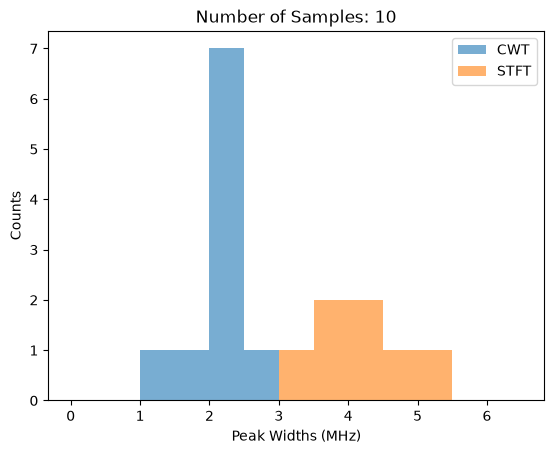

In [21]:
itr = 10
B = 20
C = 3

err = np.load(f"error_ENERGY_{itr}_magFalse_B{B}_C{C}.npy")
rng = -1
print(err)
print("CWT | STFT\nMean")
print(np.mean(err[:, :rng], axis=1))
print("STD")
print(np.std(err[:, :rng], axis=1))

bins=20

plt.hist(err[0, :rng]/1e3, label="CWT", bins=bins, alpha=0.6)#, range=(-0.25, 1))
plt.hist(err[1, :rng]/1e3, label="STFT",bins=bins,alpha=0.6)#,range=(-0.25, 1))
plt.legend()
plt.xlabel("Distance from True Energy (keV)")
plt.ylabel("Counts")
plt.title(f"B = {B}, C = {C}")
plt.show()

err = np.load(f"error_{itr}_magFalse_B{B}_C{C}.npy")
rng = -1
print(err)
print("CWT | STFT\nMean")
print(np.mean(err[:, :rng], axis=1))
print("STD")
print(np.std(err[:, :rng], axis=1))

bins=20

plt.hist(err[0, :rng], label="CWT", bins=bins, alpha=0.6, range=(-0.25, 1))
plt.hist(err[1, :rng], label="STFT",bins=bins,alpha=0.6,range=(-0.25, 1))
plt.legend()
plt.xlabel("Distance from True Frequency (MHz) - metadata")
plt.ylabel("Counts")
plt.title(f"B = {B}, C = {C}")
plt.show()

err = np.load(f"error_FFT_{itr}_magFalse_B{B}_C{C}.npy")
rng = -1
print(err)
print("CWT | STFT\nMean")
print(np.mean(err[:, :rng], axis=1))
print("STD")
print(np.std(err[:, :rng], axis=1))

bins=20

plt.hist(err[0, :rng], label="CWT", bins=bins, alpha=0.6, range=(-1, 1))
plt.hist(err[1, :rng], label="STFT",bins=bins,alpha=0.6,range=(-1, 1))
plt.legend()
plt.xlabel("Distance from True Frequency (MHz) - FFT")
plt.ylabel("Counts")
plt.title(f"Number of Samples: {itr}")
plt.show()


widths = np.load(f"FWHMs_{itr}_magFalse_B20_C3.npy")/1e6
print(widths)
print("CWT | STFT\nMean")
print(np.mean(widths, axis=1))
print("STD")
print(np.std(widths, axis=1))

bins=np.arange(0, 7, 0.5)

plt.hist(widths[0], label="CWT", bins=bins, alpha=0.6)
plt.hist(widths[1], label="STFT",bins=bins, alpha=0.6)
plt.legend()
plt.xlabel("Peak Widths (MHz)")
plt.ylabel("Counts")
plt.title(f"Number of Samples: {itr}")
plt.show()

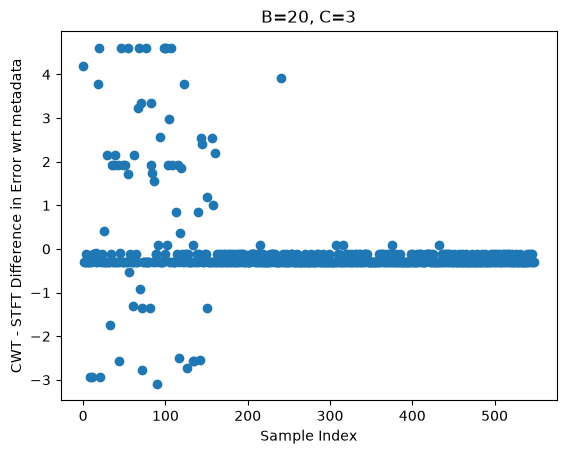

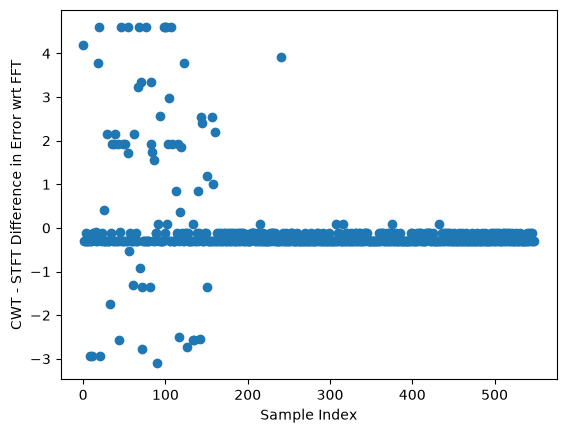

In [10]:
B = 20
C = 3
err = np.load(f"error_{itr}_magFalse_B{B}_C{C}.npy")
x = err[0]
y = err[1]
rng1 = 0
rng2 = -1
plt.scatter(range(len(x-y))[rng1:rng2], x[rng1:rng2]-y[rng1:rng2])
plt.xlabel("Sample Index")
plt.ylabel("CWT - STFT Difference in Error wrt metadata")
plt.title(f"B={B}, C={C}")
plt.show()

#plt.hist(x[rng1:rng2]-y[rng1:rng2])
#plt.show()

err = np.load(f"error_FFT_{itr}_magFalse_B20_C3.npy")
x = err[0]
y = err[1]
rng1 = 0
rng2 = -1
plt.scatter(range(len(x-y))[rng1:rng2], x[rng1:rng2]-y[rng1:rng2])
plt.xlabel("Sample Index")
plt.ylabel("CWT - STFT Difference in Error wrt FFT")
plt.show()

#plt.hist(x[rng1:rng2]-y[rng1:rng2])
#plt.show()

In [9]:
print(x[358], y[358])

-15.715810370676905 0.0908203125


In [11]:
utils.sample_get(10)

In [35]:
I = np.load("data/I_10.npy")
metadata = utils.get_quantities("data/metadata_10.json")
f_actual = metadata[2]
print(f_actual/1e6)
fs = float(metadata[0])*1e6
Q = np.load("data/Q_10.npy")

143.06797319999998


In [36]:
I.size

3500000

In [37]:
start = metadata[1][0, 0]
end = metadata[1][1, 0]
print(start, end)
idx = int(fs*start)
edx = int(fs*end)
print(idx, edx)
#idx = 0
#edx = -1

0.000406551 0.000684037
163840 275666


### Signal parameters

In [38]:
signal_raw = I[idx:edx].astype(np.float64) + 1j * Q[idx:edx].astype(np.float64)
fs = 403e6                      
T  = float(signal_raw.size)/fs
N  = signal_raw.size
t  = np.arange(N) / fs

### Downmixing signal

In [39]:
signal_locust = signal_raw * (-1.0)**np.arange(N)

ft = 31e6
f_mix = f_actual-ft                    # Hz -- tracks will land at ~142 - 135 = 7 MHz
signal = signal_locust * np.exp(-1j * 2*np.pi * f_mix * t)
 
print(f"Loaded {N} complex samples, {T*1e3:.3f} ms at {fs/1e6:.1f} MS/s")
print(f"Mixing down by {f_mix/1e6:.1f} MHz; tracks should land at "
      f"{(f_actual - f_mix)/1e6:.1f} MHz post-mix")

t_center = 0.0015     # seconds -- time where there is a track
window   = 5e-3       # 5 ms around it
i0 = max(0, int((t_center - window/2) * fs))
i1 = min(N, int((t_center + window/2) * fs))
signal = signal[i0:i1]
signal_locust = signal_locust[i0:i1]
N = len(signal)
t = np.arange(N) / fs
print(f"Sliced to {N} samples = {N/fs*1e3:.2f} ms")

Loaded 111826 complex samples, 0.277 ms at 403.0 MS/s
Mixing down by 112.1 MHz; tracks should land at 31.0 MHz post-mix
Sliced to 111826 samples = 0.28 ms


### FFT

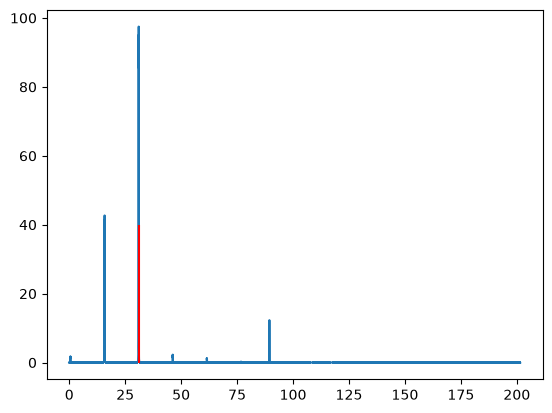

In [40]:
vals = np.abs(np.fft.fft(signal))
freqs = np.fft.fftfreq(N, 1/fs)/1e6

plt.plot(freqs[:N//2], vals[:N//2])
plt.vlines([31], 0, 40, color="red")
plt.show()

### Plotting STFT, can be replaced with STFT_viz notebook

Record length    : 111826 samples = 0.277 ms
Window length    : 1024 samples = 2.54 us
Time resolution  : ~2.54 us per STFT frame
Freq resolution  : ~393.55 kHz per bin


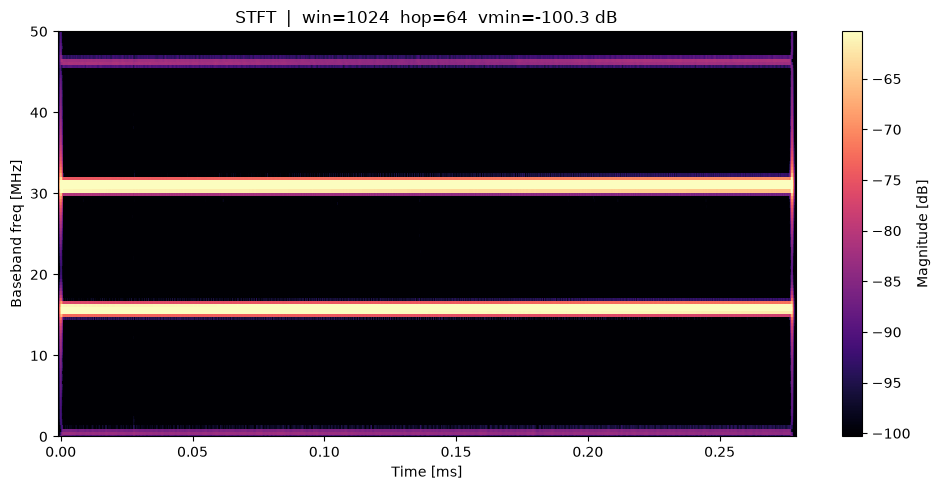

In [41]:
N = len(signal)
win_len =  min(1024, N // 8)     
hop     = max(1, win_len // 16)

print(f"Record length    : {N} samples = {N/fs*1e3:.3f} ms")
print(f"Window length    : {win_len} samples = {win_len/fs*1e6:.2f} us")
print(f"Time resolution  : ~{win_len/fs*1e6:.2f} us per STFT frame")
print(f"Freq resolution  : ~{fs/win_len/1e3:.2f} kHz per bin")

win = gaussian(win_len, std=win_len/6, sym=True)
SFT = ShortTimeFFT(win, hop=hop, fs=fs, fft_mode='centered',
                   scale_to='magnitude')
Sxx = SFT.stft(signal)
f_stft = SFT.f
t_stft = SFT.t(N)

mag_db = 20*np.log10(np.abs(Sxx) + 1e-12)
vmax = np.percentile(mag_db, 99.5)
vmin = vmax - 40          # 40 dB dynamic range

fig, ax = plt.subplots(figsize=(10, 5))
pcm = ax.pcolormesh(t_stft*1e3, f_stft/1e6, mag_db,
                    shading='auto', cmap='magma', vmin=vmin, vmax=vmax)
ax.set_xlabel('Time [ms]'); ax.set_ylabel('Baseband freq [MHz]')
ax.set_title(f'STFT  |  win={win_len}  hop={hop}  vmin={vmin:.1f} dB')
#ax.set_xlim(0.0, 2.0)
ax.set_ylim(0, 50)
fig.colorbar(pcm, ax=ax, label='Magnitude [dB]')
plt.tight_layout(); plt.show()

In [43]:
from extract_lfa_b_field import *

time_weighted_average("/nfs/roberts/pi/pi_kmh66/trs58/Wavelet_data/Trap_CCA_long_trap_44_UNetScattering_1/results/1230826107503-191/KassCavitySeed600_Angle88.66666666666667_0.001_CCA_long_trap_44Output.root", t_min=0, t_max=1/fs)

FileNotFoundError: [Errno 2] No such file or directory: '/nfs/roberts/pi/pi_kmh66/trs58/Wavelet_data/Trap_CCA_long_trap_44_UNetScattering_1/results/1230826107503-191/KassCavitySeed600_Angle88.66666666666667_0.001_CCA_long_trap_44Output.root'

### Wavelet parameter choices

In [44]:
B, C    = 20.0, 3.0
wavelet = f'cmor{B}-{C}'
 
# Band of interest: a bit below the lowest post-mix track to a bit above
# the highest. Post-mix tracks are at ~7 MHz; give generous margin.
fmin     = 50e5               # 500 kHz; stay clear of DC artifacts
fmax     = 50e6               # covers tracks + sidebands with headroom
n_voices = 96
 
freqs_pos = np.logspace(np.log10(fmin), np.log10(fmax), n_voices)
scales    = pywt.frequency2scale(wavelet, freqs_pos / fs)
 
assert scales.min() >= 1.0, (
    f"Smallest scale {scales.min():.2f} < 1. Lower fmax or increase fs."
)
 
sigma_t_fmin  = np.sqrt(B/2) * C / fmin
sigma_f_10M   = 10e6 / (np.pi * C * np.sqrt(2*B))
sigma_f_fmax  = fmax / (np.pi * C * np.sqrt(2*B))
print(f"Wavelet        : {wavelet}")
print(f"Scale range    : {scales.min():.2f} -> {scales.max():.2f}")
print(f"Freq range     : {fmin/1e6:.2f} -> {fmax/1e6:.2f} MHz")
print(f"sigma_t @ fmin : {sigma_t_fmin*1e6:.2f} us  (tracks ~1000-5000 us)")
print(f"sigma_f @ 10M  : {sigma_f_10M/1e3:.1f} kHz  (at track location)")
print(f"sigma_f @ fmax : {sigma_f_fmax/1e3:.1f} kHz")

Wavelet        : cmor20.0-3.0
Scale range    : 24.18 -> 241.80
Freq range     : 5.00 -> 50.00 MHz
sigma_t @ fmin : 1.90 us  (tracks ~1000-5000 us)
sigma_f @ 10M  : 167.8 kHz  (at track location)
sigma_f @ fmax : 838.8 kHz


### Creating scaleogram

In [45]:
coefs, f_returned = pywt.cwt(
    signal, scales, wavelet, sampling_period=1/fs, method='fft'
)
mag = np.abs(coefs)
 
print(f"Scaleogram shape: {mag.shape}  (freq bins x time samples)")
print(f"Memory: {mag.nbytes/1e6:.1f} MB")

Scaleogram shape: (96, 111826)  (freq bins x time samples)
Memory: 85.9 MB


In [46]:
f_returned/1e6

array([ 5.        ,  5.1226693 ,  5.24834815,  5.37711038,  5.50903165,
        5.64418946,  5.78266321,  5.92453426,  6.06988595,  6.21880367,
        6.37137493,  6.52768935,  6.68783876,  6.85191725,  7.02002123,
        7.19224944,  7.36870308,  7.5494858 ,  7.73470383,  7.92446596,
        8.1188837 ,  8.31807125,  8.52214564,  8.73122676,  8.94543745,
        9.16490355,  9.38975401,  9.62012091,  9.85613961, 10.09794875,
       10.34569041, 10.59951012, 10.85955701, 11.12598385, 11.39894718,
       11.67860735, 11.96512866, 12.25867944, 12.55943216, 12.8675635 ,
       13.18325449, 13.50669061, 13.83806185, 14.17756292, 14.52539325,
       14.88175721, 15.24686415, 15.62092857, 16.00417023, 16.3968143 ,
       16.79909143, 17.21123798, 17.63349607, 18.06611378, 18.50934528,
       18.96345095, 19.42869759, 19.90535853, 20.39371379, 20.8940503 ,
       21.40666199, 21.93185003, 22.46992295, 23.02119688, 23.58599569,
       24.16465119, 24.75750335, 25.36490045, 25.98719935, 26.62

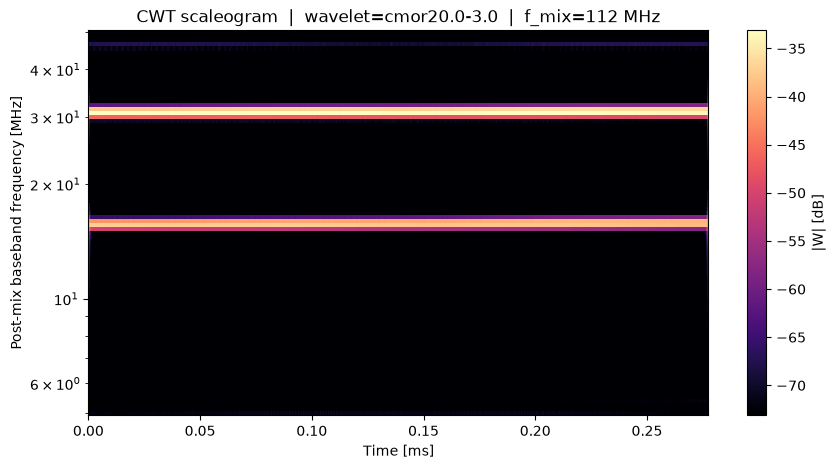

In [47]:
t_plot = np.arange(mag.shape[1]) / fs
mag_db = 20*np.log10(mag + 1e-12)
vmax   = np.percentile(mag_db, 99.5)
vmin   = vmax - 40
 
fig, ax = plt.subplots(figsize=(10, 5))
pcm = ax.pcolormesh(t_plot*1e3, freqs_pos/1e6, mag_db,
                    shading='auto', cmap='magma', vmin=vmin, vmax=vmax)
ax.set_xlabel('Time [ms]')
ax.set_ylabel('Post-mix baseband frequency [MHz]')
ax.set_yscale('log')
#plt.xlim(0.4, .9)
ax.set_title(f'CWT scaleogram  |  wavelet={wavelet}  |  f_mix={f_mix/1e6:.0f} MHz')
fig.colorbar(pcm, ax=ax, label='|W| [dB]')
plt.show()

In [49]:
print(1/fs, t_stft[1]-t_stft[0], t_plot[1]-t_plot[0])

2.4813895781637716e-09 1.5880893300248135e-07 2.4813895781637716e-09


In [22]:
bg = np.mean(mag)/2
mean = np.mean(mag, axis=1)

### Finding Sidebands + Reconstruction Error

In [23]:
t_plot = np.arange(mag.shape[1]) / fs
idx = N//5
print("At time:", t_plot[idx]*1e3, "ms")
print("We have frequency bands of:")
freq_cands = np.where(np.abs(freqs_pos - ft) <= 5e6)[0]
cands = mean[freq_cands]
freqs_pos[freq_cands[np.argmax(cands)]]/1e6

At time: 0.20913895781637717 ms
We have frequency bands of:


np.float64(30.79241055330133)

In [24]:
f_target = ft/1e6
print("Target Frequency:", f_target)

t_cwt = np.arange(mag.shape[1]) / fs
idx_cwt = 5000
print("At CWT time:", t_cwt[idx_cwt]*1e3, "ms")
idx_stft = max(np.where(np.round(t_stft*1e3 - t_cwt[idx_cwt]*1e3, 3) == 0.0)[0])
print("At STFT time:", t_stft[idx_stft]*1e3, "ms")

magcwt = mag[:, idx_cwt]
magstft = np.abs(Sxx[:, idx_stft])

f_CWT = freqs_pos[np.argmax(magcwt)]/1e6
print(f"\nFrequency CWT: {f_CWT}, \nDifference Error: {f_CWT-f_target}\n")

f_STFT = f_stft[np.argmax(magstft)]/1e6
print(f"Frequency STFT: {f_STFT}, \nDifference Error: {f_STFT-f_target}")

Target Frequency: 31.0
At CWT time: 0.012406947890818858 ms
At STFT time: 0.012863523573200992 ms

Frequency CWT: 30.79241055330133, 
Difference Error: -0.20758944669866963

Frequency STFT: 30.697265625, 
Difference Error: -0.302734375


In [26]:
mag = np.abs(coefs)
        
    
means_CWT = np.mean(mag, axis=1)
#means_STFT = np.mean(np.abs(Sxx), axis=1)

f_CWT = freqs_pos[np.argmax(means_CWT)]/1e6
f_CWT

np.float64(30.79241055330133)

### Marginalization

In [27]:
def map_index_to_x(x, a, out):
    returns = []
    for i in out:
        subreturn = []
        for j in i:
            idx = int(j)
            diff = j-idx
            subreturn.append(x[idx] + a*diff)
        returns.append(subreturn)

    returns = np.array(returns).T

    return returns

[45 75 93]
Peak Frequencies in order: [14.88175721 30.79241055 47.63403515]
Predicted Widths in Order: [2.14796891e-06 1.88534052e-06 1.89239054e-06]


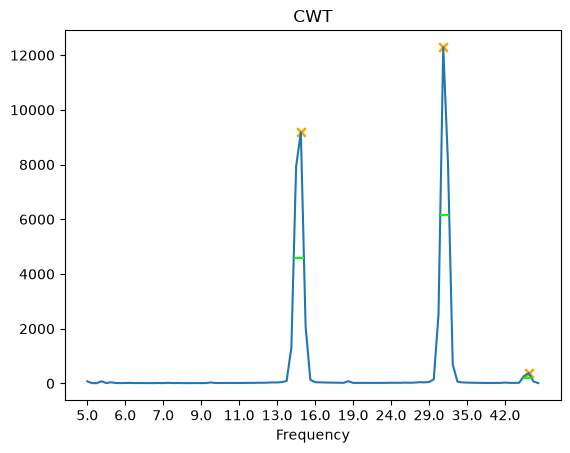

[14881757.20815659 30792410.55330133 47634035.14509908]
0.0010456947890818858
0.0010468684863523573


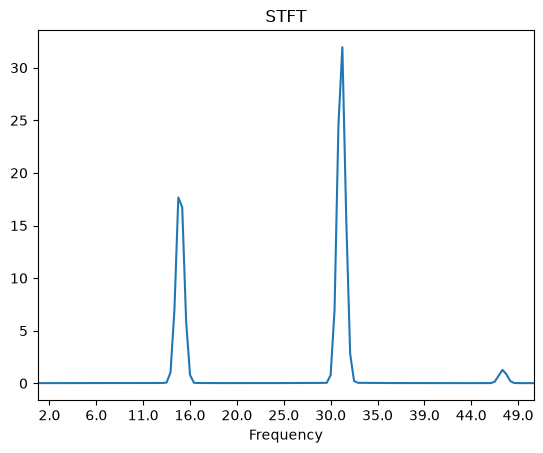

In [28]:
from scipy.signal import find_peaks, peak_widths

end = metadata[1][1, 0]
idx_cwt = max(np.where(np.round(t_cwt - end, 1) == 0.0)[0])
m_CWT = np.sum(mag[:, :idx_cwt], axis=1)
fullxrange = np.array(range(len(m_CWT)))

plt.plot(m_CWT)
plt.xlabel("Frequency")
plt.title("CWT")
xrange = np.arange(0, len(m_CWT), 8)
plt.xticks(xrange, np.round(freqs_pos[xrange]/1e6, 0))

a_f = 1
n = m_CWT
peaks = find_peaks(n)[0]
peaks = peaks[np.where(n[peaks] >= 100)[0]]
p_idx = n[peaks]
print(peaks)
print(f"Peak Frequencies in order: {freqs_pos[peaks]/1e6}")
widths = np.array(peak_widths(n, peaks, rel_height=0.5))

f_bounds = map_index_to_x(fullxrange, a_f, widths[2:])
f_widths = np.zeros((len(f_bounds[:, 0]), 4))
f_widths[:, 0] = f_bounds[:, 1] - f_bounds[:, 0]
f_widths[:, 1] = widths[1]
f_widths[:, 2:] = f_bounds
    
print(f"Predicted Widths in Order: {f_widths[:, 0]/1e6}")
for j in range(len(f_bounds[:, 0])):
    plt.hlines(*f_widths[j, 1:], color="lime")
    plt.scatter(fullxrange[peaks], n[peaks],color="orange", marker="x")
plt.show()

print(freqs_pos[peaks])

print(t_plot[idx_cwt])

idx_stft = max(np.where(np.round(t_stft - end, 2) == 0 )[0])
print(t_stft[idx_stft])
m_STFT = np.sum(np.abs(Sxx)[:, :idx_stft], axis=1)
plt.plot(m_STFT)
plt.xlabel("Frequency")
plt.title("STFT")
xrange = np.arange(0, len(m_STFT), 12)
plt.xticks(xrange,np.round(f_stft[xrange]/1e6, 0))
plt.xlim(min(np.where(f_stft/1e6 > 0)[0]), min(np.where(f_stft/1e6 - 50 > 1e-3)[0]))
plt.show()



### Plotting scaleogram

### Plotting wavelet properties to help tune parameters

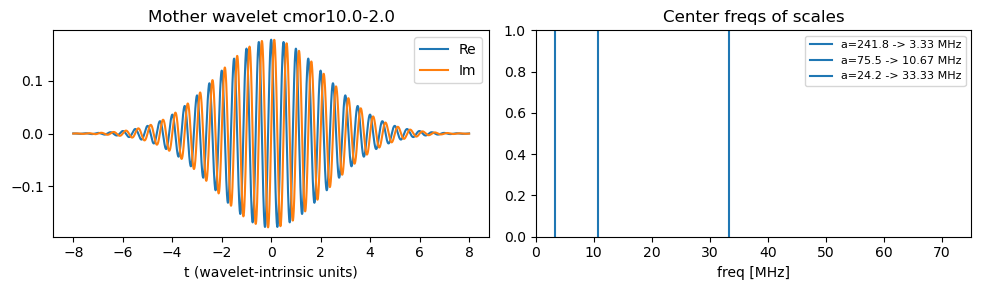

In [26]:
B, C    = 10.0, 2.0
wavelet = f'cmor{B}-{C}'
wav     = pywt.ContinuousWavelet(wavelet)
psi, x  = wav.wavefun(level=12)
 
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(x, np.real(psi), label='Re')
axes[0].plot(x, np.imag(psi), label='Im')
axes[0].set_title(f'Mother wavelet {wavelet}'); axes[0].legend()
axes[0].set_xlabel('t (wavelet-intrinsic units)')
 
for a in [scales[0], scales[len(scales)//2], scales[-1]]:
    fc = pywt.scale2frequency(wavelet, a) * fs
    axes[1].axvline(fc/1e6, label=f'a={a:.1f} -> {fc/1e6:.2f} MHz')
axes[1].set_xlabel('freq [MHz]'); axes[1].set_title('Center freqs of scales')
axes[1].legend(fontsize=8);
axes[1].set_xlim(0, fmax*1.5/1e6)
plt.tight_layout(); plt.show()